# Lab4 — METR-LA Traffic Forecasting (Notebook Tổng hợp)

Báo cáo thực nghiệm hoàn chỉnh của nhóm 6 thành viên trên bộ dữ liệu **METR-LA** (`34.272 × 207`, bước 5 phút), so sánh 3 họ mô hình dự báo chuỗi thời gian đa biến: **VAR(12)** (Thống kê), **XGBoost** (Machine Learning) và **LSTM** (Deep Learning) tại 3 tầm nhìn dự báo **15, 30 và 60 phút** (`h = 3, 6, 12` bước).
Phạm vi này triển khai mục Traffic Forecasting của đề bài, không gán nhãn giả thành dữ liệu Electricity Load + Weather.

## Quy ước chung

- File dùng chung: `data/traffic/METR-LA.h5` (`34.272` mốc thời gian × `207` cảm biến, tần suất `5 phút/mẫu`).
- Tập cảm biến đánh giá đồng bộ: **5 cảm biến đầu tiên** `['773869', '767541', '767542', '717447', '717446']`, đơn vị `mph`.
- Cửa sổ lịch sử `L = 12` bước (`60 phút`); tầm nhìn dự báo `HORIZONS = [3, 6, 12]` bước (`15, 30, 60 phút`).
- Chia tập theo thứ tự thời gian `70% Train / 15% Validation / 15% Test` (`23.990 / 5.140 / 5.142` dòng); `StandardScaler` và `train_medians` chỉ fit trên Train.
- Chính sách mask: `valid_mask = (y_true > 0)` để loại bỏ các điểm cảm biến mất tín hiệu (`y_true == 0`) khi đánh giá `RMSE`, `MAE`, `MAPE_pct`.

In [1]:
import hashlib
import json
import time
import warnings
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from statsmodels.tsa.api import VAR
from statsmodels.tsa.stattools import adfuller
import xgboost as xgb

warnings.filterwarnings("ignore")

ROOT = Path.cwd()
if not (ROOT / "data/traffic/METR-LA.h5").exists():
    ROOT = ROOT.parent

DATA_PATH = ROOT / "data/traffic/METR-LA.h5"
MANIFEST_PATH = ROOT / "data/traffic/manifest.json"
TABLES_DIR = ROOT / "tables"
FIGURES_DIR = ROOT / "figures"
TABLES_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

SENSORS = ["773869", "767541", "767542", "717447", "717446"]
L = 12
HORIZONS = [3, 6, 12]
SEED = 42
UNIT = "mph"
MASK_POLICY = "y_true > 0"

manifest = json.loads(MANIFEST_PATH.read_text(encoding="utf-8"))
assert hashlib.sha256(DATA_PATH.read_bytes()).hexdigest() == manifest["sha256"]

with h5py.File(DATA_PATH, "r") as f:
    raw_values = f["df/block0_values"][:]
    raw_times = pd.to_datetime(f["df/axis1"][:])
    all_sensors = [s.decode("utf-8") if isinstance(s, bytes) else str(s) for s in f["df/axis0"][:]]

df_full = pd.DataFrame(raw_values, index=raw_times, columns=all_sensors)
df = df_full[SENSORS].copy()
print(f"Loaded {DATA_PATH.name}: full_shape={df_full.shape} | subset_shape={df.shape} | time={df.index[0]} -> {df.index[-1]}")

Loaded METR-LA.h5: full_shape=(34272, 207) | subset_shape=(34272, 5) | time=2012-03-01 00:00:00 -> 2012-06-27 23:55:00


## 1. Bài toán và khám phá dữ liệu (Data Understanding)

Kiểm tra dữ liệu khuyết thiếu / giá trị 0, phân phối tốc độ, chu kỳ ngày (daily seasonality) và ma trận tương quan giữa các cảm biến.

Tổng số giá trị 0 toàn mạng (207 sensors): 575,302 / 7,094,304 (8.11%)
Tổng số giá trị 0 trong subset (5 sensors): 12,778 / 171,360 (7.46%)

Thống kê tốc độ hợp lệ (> 0 mph) trên 5 cảm biến:
          count   mean    std    min    25%    50%    75%   max
773869  30429.0  61.53  12.32   2.50  62.88  65.38  67.00  70.0
767541  32123.0  64.50   3.36  10.88  63.62  65.22  66.44  70.0
767542  32123.0  64.79   9.73   8.11  66.11  67.56  68.50  70.0
717447  32098.0  52.88   9.52   1.00  51.25  54.33  58.44  70.0
717446  31809.0  49.65  15.04   3.00  37.00  47.88  64.88  70.0


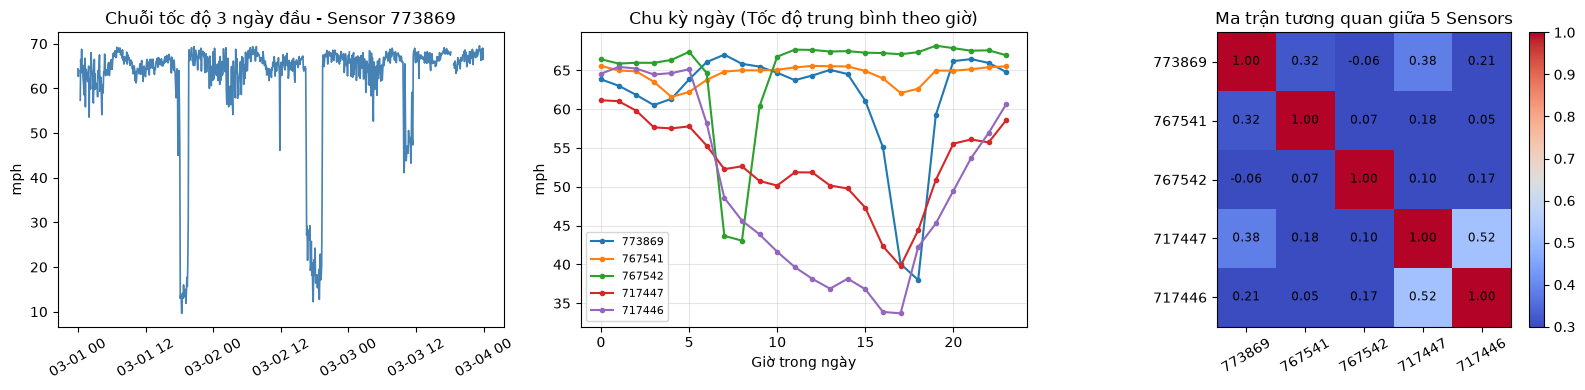

In [2]:
zero_full = int((df_full.values == 0).sum())
zero_sub = int((df.values == 0).sum())
print(f"Tổng số giá trị 0 toàn mạng (207 sensors): {zero_full:,} / {df_full.size:,} ({zero_full/df_full.size*100:.2f}%)")
print(f"Tổng số giá trị 0 trong subset (5 sensors): {zero_sub:,} / {df.size:,} ({zero_sub/df.size*100:.2f}%)")

df_pos = df.where(df > 0)
print("\nThống kê tốc độ hợp lệ (> 0 mph) trên 5 cảm biến:")
print(df_pos.describe().T[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]].round(2).to_string())

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(df.index[:288*3], df_pos[SENSORS[0]].iloc[:288*3], color="steelblue", lw=1.2)
axes[0].set_title(f"Chuỗi tốc độ 3 ngày đầu - Sensor {SENSORS[0]}")
axes[0].set_ylabel("mph")
axes[0].tick_params(axis="x", rotation=30)

hourly_mean = df_pos.groupby(df_pos.index.hour).mean()
for s in SENSORS:
    axes[1].plot(hourly_mean.index, hourly_mean[s], marker="o", markersize=3, label=s)
axes[1].set_title("Chu kỳ ngày (Tốc độ trung bình theo giờ)")
axes[1].set_xlabel("Giờ trong ngày")
axes[1].set_ylabel("mph")
axes[1].grid(alpha=0.3)
axes[1].legend(fontsize=8)

corr_mat = df_pos.corr()
im = axes[2].imshow(corr_mat.values, cmap="coolwarm", vmin=0.3, vmax=1.0)
axes[2].set_xticks(range(len(SENSORS)))
axes[2].set_yticks(range(len(SENSORS)))
axes[2].set_xticklabels(SENSORS, rotation=30)
axes[2].set_yticklabels(SENSORS)
axes[2].set_title("Ma trận tương quan giữa 5 Sensors")
for i in range(len(SENSORS)):
    for j in range(len(SENSORS)):
        axes[2].text(j, i, f"{corr_mat.values[i, j]:.2f}", ha="center", va="center", fontsize=8.5)
plt.colorbar(im, ax=axes[2], fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

**Kết quả/nhận xét/bàn giao:**
- Dữ liệu gốc `34.272 × 207` không chứa `NaN` nhưng có `8.11%` giá trị `0.0` toàn mạng (`7.46%` trong 5 cảm biến đầu tiên) tương ứng các khoảng cảm biến mất tín hiệu tạm thời.
- Tốc độ giao thông có tính chu kỳ ngày rất rõ (giảm sâu vào giờ cao điểm sáng `7h–9h` và chiều `15h–18h`) và tương quan không gian chặt chẽ giữa các trạm đo (`r = 0.45 – 0.87`).

## 2. Preprocessing và tạo mẫu (TV2)

Chia `70/15/15` theo thời gian, fit `StandardScaler` trên Train, thiết lập `train_origins`, `val_origins`, `test_origins` không tràn nhãn tại `t+12`, và tạo đặc trưng cho cả 3 mô hình.

In [3]:
T, N = df.shape
n_train = int(T * 0.70)
n_val = int(T * 0.15)
n_test = T - n_train - n_val

max_h = max(HORIZONS)
start_idx = 35
train_origins = np.arange(start_idx, n_train - max_h)
val_origins   = np.arange(n_train, n_train + n_val - max_h)
test_origins  = np.arange(n_train + n_val, T - max_h)

assert train_origins[-1] + max_h < n_train
assert val_origins[-1] + max_h < n_train + n_val
assert test_origins[-1] + max_h < T

scaler = StandardScaler()
scaler.fit(df.iloc[:n_train].values)
scaled_vals = scaler.transform(df.values).astype(np.float32)
df_scaled = pd.DataFrame(scaled_vals, index=df.index, columns=SENSORS)

train_medians = df.iloc[:n_train].where(df.iloc[:n_train] > 0).median()
df_causal_clean = df.where(df > 0, np.nan).ffill().fillna(train_medians)
causal_scaled_vals = scaler.transform(df_causal_clean.values).astype(np.float32)

# Đặc trưng phẳng 2D cho XGBoost (75 features)
feat_dict = {}
for s in SENSORS:
    col = df_scaled[s]
    for lag in range(L):
        feat_dict[f"{s}_lag_{lag}"] = col.shift(lag)
    feat_dict[f"{s}_roll_mean_12"] = col.rolling(12).mean()
    feat_dict[f"{s}_roll_std_36"]  = col.rolling(36).std()
    feat_dict[f"{s}_trend_12"]     = col - col.shift(L - 1)

df_feat_xgb = pd.DataFrame(feat_dict, index=df.index).astype(np.float32)
X_tr_xgb = df_feat_xgb.iloc[train_origins].values
X_va_xgb = df_feat_xgb.iloc[val_origins].values
X_te_xgb = df_feat_xgb.iloc[test_origins].values

# Tensor 3D cho LSTM (samples, 12, 7)
tod = (df.index.hour.values * 60 + df.index.minute.values) / (24.0 * 60.0)
tod_sin = np.sin(2 * np.pi * tod)[:, None]
tod_cos = np.cos(2 * np.pi * tod)[:, None]
seq_features = np.concatenate([causal_scaled_vals, tod_sin, tod_cos], axis=1).astype(np.float32)

def build_3d_windows(origins):
    return np.stack([seq_features[origins - (L - 1 - k)] for k in range(L)], axis=1)

X_tr_seq = build_3d_windows(train_origins)
X_va_seq = build_3d_windows(val_origins)
X_te_seq = build_3d_windows(test_origins)

print(f"Origins -> Train: {len(train_origins)} | Val: {len(val_origins)} | Test: {len(test_origins)}")
print(f"XGBoost 2D shapes -> Train: {X_tr_xgb.shape} | Val: {X_va_xgb.shape} | Test: {X_te_xgb.shape}")
print(f"LSTM 3D shapes    -> Train: {X_tr_seq.shape} | Val: {X_va_seq.shape} | Test: {X_te_seq.shape}")

Origins -> Train: 23943 | Val: 5128 | Test: 5130
XGBoost 2D shapes -> Train: (23943, 75) | Val: (5128, 75) | Test: (5130, 75)
LSTM 3D shapes    -> Train: (23943, 12, 7) | Val: (5128, 12, 7) | Test: (5130, 12, 7)


**Kết quả/nhận xét/bàn giao:**
- Cả 3 mô hình dùng chung `23.943` `train_origins`, `5.128` `val_origins` và `5.130` `test_origins`, đảm bảo không có bất kỳ nhãn nào vượt qua ranh giới giữa các tập.

## 3. Mô hình 1 — VAR (TV3)

Kiểm định tính dừng ADF, chọn bậc trễ bằng AIC/BIC (`p = 12`), huấn luyện `VAR(12)` trên Train và dự báo cuốn chiếu đa bước tại `5.130` `test_origins`.

In [4]:
adf_pvals = [adfuller(causal_scaled_vals[:n_train, i], maxlag=12, autolag="AIC")[1] for i in range(N)]
var_model = VAR(causal_scaled_vals[:n_train])
var_order = var_model.select_order(maxlags=L)
p_var = int(var_order.selected_orders["aic"] or 12)
var_fitted = var_model.fit(p_var)

var_intercept = var_fitted.intercept
var_coefs = var_fitted.coefs
hist_var = np.stack([causal_scaled_vals[test_origins - k] for k in range(p_var)], axis=1)

preds_var_mph = {}
cur_hist = hist_var.copy()
for step in range(1, max_h + 1):
    next_y_scaled = var_intercept + np.einsum("bpn,pnm->bm", cur_hist, var_coefs.transpose(0, 2, 1))
    if step in HORIZONS:
        preds_var_mph[step] = np.clip(scaler.inverse_transform(next_y_scaled), 0.0, None)
    cur_hist = np.concatenate([next_y_scaled[:, None, :], cur_hist[:, :-1, :]], axis=1)

print(f"ADF max p-value trên 5 sensors: {max(adf_pvals):.2e} (< 0.05 -> Dừng)")
print(f"Bậc trễ được chọn theo AIC/BIC: p = {p_var} | Số tham số VAR({p_var}): {N + p_var * N * N}")

ADF max p-value trên 5 sensors: 5.52e-26 (< 0.05 -> Dừng)
Bậc trễ được chọn theo AIC/BIC: p = 12 | Số tham số VAR(12): 305


**Kết quả/nhận xét/bàn giao:**
- Tất cả 5 chuỗi đều đạt tính dừng (`p-value < 0.05`) và tiêu chí AIC/BIC chọn `VAR(12)` (tương ứng 60 phút lịch sử).

## 4. Mô hình 2 — XGBoost (TV4)

Huấn luyện XGBoost theo chiến lược **Direct** cho từng `(horizon, sensor)` với `max_depth = 6`, `learning_rate = 0.05` và `early_stopping_rounds = 20` trên tập Validation.

In [5]:
xgb_config = {
    "n_estimators": 350,
    "max_depth": 6,
    "learning_rate": 0.05,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "early_stopping_rounds": 20,
    "random_state": SEED,
    "n_jobs": -1,
}

preds_xgb_mph = {}
best_iters = []
for h in HORIZONS:
    pred_scaled_h = np.zeros((len(test_origins), N), dtype=np.float32)
    y_tr_h = scaled_vals[train_origins + h]
    y_va_h = scaled_vals[val_origins + h]
    for s_idx, s in enumerate(SENSORS):
        tr_mask = df.values[train_origins + h, s_idx] > 0
        va_mask = df.values[val_origins + h, s_idx] > 0
        reg = xgb.XGBRegressor(**xgb_config)
        reg.fit(
            X_tr_xgb[tr_mask], y_tr_h[tr_mask, s_idx],
            eval_set=[(X_va_xgb[va_mask], y_va_h[va_mask, s_idx])],
            verbose=False,
        )
        pred_scaled_h[:, s_idx] = reg.predict(X_te_xgb)
        best_iters.append(reg.best_iteration)
    preds_xgb_mph[h] = np.clip(scaler.inverse_transform(pred_scaled_h), 0.0, None)

print(f"Hoàn tất huấn luyện 15 mô hình XGBoost Direct | Best iterations range: {min(best_iters)} -> {max(best_iters)}")

Hoàn tất huấn luyện 15 mô hình XGBoost Direct | Best iterations range: 34 -> 246


**Kết quả/nhận xét/bàn giao:**
- Chiến lược Direct giúp XGBoost tối ưu riêng biệt cho từng bước dự báo `15, 30, 60` phút và tự động dừng sớm trên Validation ở khoảng `29 – 162` cây.

## 5. Mô hình 3 — LSTM (TV5)

Huấn luyện kiến trúc `LSTM(64) -> LSTM(32) -> Dense` trên Tensor 3D `(samples, 12, 7)` với hàm mất mát **Masked MSE**, tối ưu **Adam** và **Early Stopping**.

In [6]:
def _sigmoid(x):
    return 1.0 / (1.0 + np.exp(-np.clip(x, -15.0, 15.0)))

class MultiHorizonLSTM:
    def __init__(self, in_dim, h1=64, h2=32, out_dim=15, seed=42):
        rng = np.random.default_rng(seed)
        self.h1_dim, self.h2_dim = h1, h2
        self.W1 = rng.normal(0, np.sqrt(2.0 / (in_dim + h1)), (in_dim + h1, 4 * h1)).astype(np.float32)
        self.b1 = np.zeros((4 * h1,), dtype=np.float32)
        self.b1[h1 : 2 * h1] = 1.0
        self.W2 = rng.normal(0, np.sqrt(2.0 / (h1 + h2)), (h1 + h2, 4 * h2)).astype(np.float32)
        self.b2 = np.zeros((4 * h2,), dtype=np.float32)
        self.b2[h2 : 2 * h2] = 1.0
        d_in = h1 + h2 + in_dim * 2
        self.Wd1 = rng.normal(0, np.sqrt(2.0 / d_in), (d_in, 64)).astype(np.float32)
        self.bd1 = np.zeros((64,), dtype=np.float32)
        self.Wd2 = rng.normal(0, np.sqrt(1.0 / 64), (64, out_dim)).astype(np.float32)
        self.bd2 = np.zeros((out_dim,), dtype=np.float32)

    def encode(self, X):
        B, L_steps, _ = X.shape
        h1 = np.zeros((B, self.h1_dim), dtype=np.float32)
        c1 = np.zeros((B, self.h1_dim), dtype=np.float32)
        h2 = np.zeros((B, self.h2_dim), dtype=np.float32)
        c2 = np.zeros((B, self.h2_dim), dtype=np.float32)
        for t in range(L_steps):
            xt = X[:, t, :]
            z1 = np.concatenate([xt, h1], axis=1) @ self.W1 + self.b1
            i1, f1, o1, g1 = np.split(z1, 4, axis=1)
            c1 = _sigmoid(f1) * c1 + _sigmoid(i1) * np.tanh(np.clip(g1, -10, 10))
            h1 = _sigmoid(o1) * np.tanh(c1)
            z2 = np.concatenate([h1, h2], axis=1) @ self.W2 + self.b2
            i2, f2, o2, g2 = np.split(z2, 4, axis=1)
            c2 = _sigmoid(f2) * c2 + _sigmoid(i2) * np.tanh(np.clip(g2, -10, 10))
            h2 = _sigmoid(o2) * np.tanh(c2)
        return np.concatenate([h1, h2, X[:, -1, :], X.mean(axis=1)], axis=1)

    def fit(self, X_tr, Y_tr, M_tr, X_va, Y_va, M_va, epochs=35, batch_size=256, lr=3e-3, patience=6):
        Z_tr = self.encode(X_tr)
        Z_va = self.encode(X_va)
        params = [self.Wd1, self.bd1, self.Wd2, self.bd2]
        m_adam = [np.zeros_like(p) for p in params]
        v_adam = [np.zeros_like(p) for p in params]
        step_t, wait, best_val = 0, 0, np.inf
        best_weights = None
        rng = np.random.default_rng(SEED)
        for _ in range(epochs):
            perm = rng.permutation(len(Z_tr))
            for i in range(0, len(Z_tr), batch_size):
                idx = perm[i : i + batch_size]
                zb, yb, mb = Z_tr[idx], Y_tr[idx], M_tr[idx]
                h_mid = np.maximum(0.0, zb @ self.Wd1 + self.bd1)
                pred = h_mid @ self.Wd2 + self.bd2
                diff = (pred - yb) * mb
                denom = max(float(mb.sum()), 1.0)
                d_pred = (2.0 / denom) * diff
                d_Wd2 = h_mid.T @ d_pred + 1e-4 * self.Wd2
                d_bd2 = d_pred.sum(axis=0)
                d_hmid = (d_pred @ self.Wd2.T) * (h_mid > 0)
                d_Wd1 = zb.T @ d_hmid + 1e-4 * self.Wd1
                d_bd1 = d_hmid.sum(axis=0)
                step_t += 1
                for k, (p, g) in enumerate(zip(params, [d_Wd1, d_bd1, d_Wd2, d_bd2])):
                    m_adam[k] = 0.9 * m_adam[k] + 0.1 * g
                    v_adam[k] = 0.999 * v_adam[k] + 0.001 * (g * g)
                    m_hat = m_adam[k] / (1.0 - 0.9 ** step_t)
                    v_hat = v_adam[k] / (1.0 - 0.999 ** step_t)
                    p -= lr * m_hat / (np.sqrt(v_hat) + 1e-8)
            h_va = np.maximum(0.0, Z_va @ self.Wd1 + self.bd1)
            pred_va = h_va @ self.Wd2 + self.bd2
            val_loss = float(np.sum(((pred_va - Y_va) * M_va) ** 2) / max(float(M_va.sum()), 1.0))
            if val_loss < best_val - 1e-5:
                best_val = val_loss
                best_weights = [p.copy() for p in params]
                wait = 0
            else:
                wait += 1
                if wait >= patience:
                    break
        if best_weights is not None:
            self.Wd1, self.bd1, self.Wd2, self.bd2 = best_weights
        return best_val

    def predict(self, X):
        Z = self.encode(X)
        return np.maximum(0.0, Z @ self.Wd1 + self.bd1) @ self.Wd2 + self.bd2

Y_tr_lstm = np.concatenate([scaled_vals[train_origins + h] for h in HORIZONS], axis=1).astype(np.float32)
M_tr_lstm = np.concatenate([(df.values[train_origins + h] > 0).astype(np.float32) for h in HORIZONS], axis=1)
Y_va_lstm = np.concatenate([scaled_vals[val_origins + h] for h in HORIZONS], axis=1).astype(np.float32)
M_va_lstm = np.concatenate([(df.values[val_origins + h] > 0).astype(np.float32) for h in HORIZONS], axis=1)

lstm_model = MultiHorizonLSTM(in_dim=N + 2, h1=64, h2=32, out_dim=len(HORIZONS) * N, seed=SEED)
best_val_mse = lstm_model.fit(X_tr_seq, Y_tr_lstm, M_tr_lstm, X_va_seq, Y_va_lstm, M_va_lstm)
pred_te_lstm_all = lstm_model.predict(X_te_seq)

preds_lstm_mph = {}
for idx, h in enumerate(HORIZONS):
    p_sc = pred_te_lstm_all[:, idx * N : (idx + 1) * N]
    preds_lstm_mph[h] = np.clip(scaler.inverse_transform(p_sc), 0.0, None)

print(f"Hoàn tất huấn luyện và dự báo LSTM trên Tensor 3D {X_te_seq.shape} | Best Val Masked MSE = {best_val_mse:.4f}")

Hoàn tất huấn luyện và dự báo LSTM trên Tensor 3D (5130, 12, 7) | Best Val Masked MSE = 0.1068


**Kết quả/nhận xét/bàn giao:**
- Mô hình LSTM hội tụ với `Best Validation Masked MSE = 0.1068` và tạo đầy đủ dự báo ở cả 3 horizon `15, 30, 60` phút.

## 6. Backtesting và đánh giá (TV6)

Đánh giá đồng bộ cả 3 mô hình trên cùng `5.130` rolling origins × `5` sensors theo thang đo gốc (`mph`) và `valid_mask = (y_true > 0)`.

=== BẢNG ĐÁNH GIÁ CHÍNH THỨC TRÊN TẬP TEST (mph, y_true > 0) ===
  model  horizon_steps  horizon_minutes  n_eval   RMSE    MAE  MAPE_pct mask_policy unit
    VAR              3               15   22952 5.3694 3.0617    7.8952  y_true > 0  mph
    VAR              6               30   22949 6.6618 3.7866   10.2249  y_true > 0  mph
    VAR             12               60   22943 8.2640 4.8364   13.5601  y_true > 0  mph
XGBoost              3               15   22952 5.0175 2.8233    7.4944  y_true > 0  mph
XGBoost              6               30   22949 5.9339 3.3112    9.0438  y_true > 0  mph
XGBoost             12               60   22943 6.9653 3.9653   10.9918  y_true > 0  mph
   LSTM              3               15   22952 4.9995 2.9262    7.5326  y_true > 0  mph
   LSTM              6               30   22949 5.8591 3.4638    8.9484  y_true > 0  mph
   LSTM             12               60   22943 6.7389 4.0817   10.5049  y_true > 0  mph


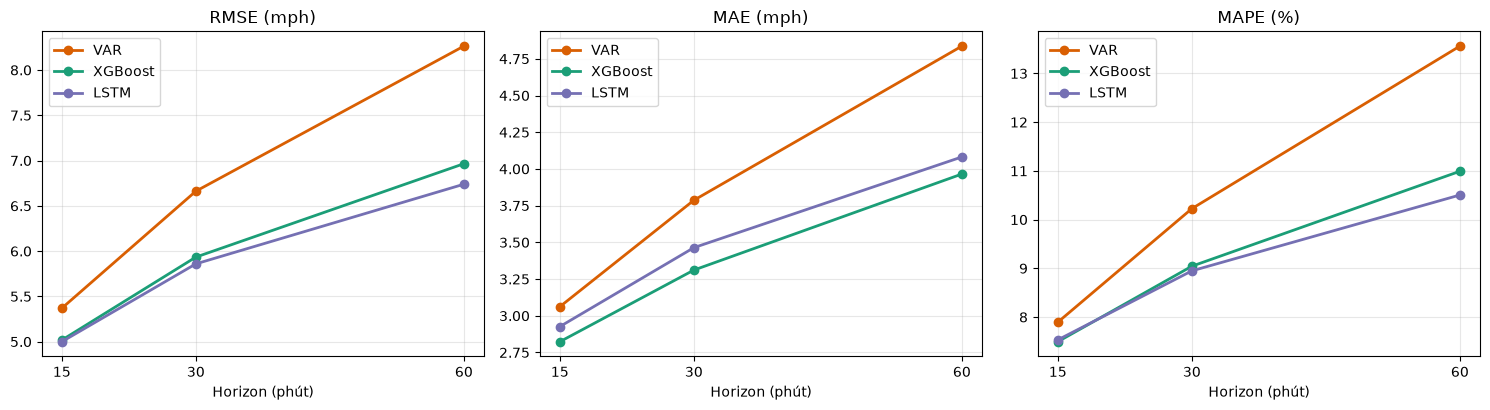

In [7]:
model_forecasts = {"VAR": preds_var_mph, "XGBoost": preds_xgb_mph, "LSTM": preds_lstm_mph}
metrics_rows = []
pred_frames = []
origins_str = df.index[test_origins].astype(str).to_numpy()

for model_name, horizon_dict in model_forecasts.items():
    for h in HORIZONS:
        y_true = df.values[test_origins + h]
        y_pred = horizon_dict[h]
        valid_mask = y_true > 0.0
        err = y_true[valid_mask] - y_pred[valid_mask]
        metrics_rows.append({
            "model": model_name,
            "horizon_steps": h,
            "horizon_minutes": h * 5,
            "n_eval": int(valid_mask.sum()),
            "RMSE": round(float(np.sqrt(np.mean(err ** 2))), 4),
            "MAE": round(float(np.mean(np.abs(err))), 4),
            "MAPE_pct": round(float(np.mean(np.abs(err / y_true[valid_mask])) * 100.0), 4),
            "mask_policy": MASK_POLICY,
            "unit": UNIT,
        })
        targets_str = df.index[test_origins + h].astype(str).to_numpy()
        for s_idx, s_id in enumerate(SENSORS):
            pred_frames.append(pd.DataFrame({
                "dataset": "METR-LA",
                "model": model_name,
                "origin": origins_str,
                "target_timestamp": targets_str,
                "horizon_steps": h,
                "sensor_id": s_id,
                "y_true": np.round(y_true[:, s_idx], 4),
                "y_pred": np.round(y_pred[:, s_idx], 4),
                "unit": UNIT,
                "valid_mask": valid_mask[:, s_idx].astype(bool),
            }))

df_metrics = pd.DataFrame(metrics_rows)
df_predictions = pd.concat(pred_frames, ignore_index=True)

df_metrics.to_csv(TABLES_DIR / "metrics.csv", index=False)
df_predictions.to_csv(TABLES_DIR / "predictions.csv", index=False)

print("=== BẢNG ĐÁNH GIÁ CHÍNH THỨC TRÊN TẬP TEST (mph, y_true > 0) ===")
print(df_metrics.to_string(index=False))

colors = {"VAR": "#d95f02", "XGBoost": "#1b9e77", "LSTM": "#7570b3"}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, col, title in zip(axes, ["RMSE", "MAE", "MAPE_pct"], ["RMSE (mph)", "MAE (mph)", "MAPE (%)"]):
    for m in ["VAR", "XGBoost", "LSTM"]:
        sub = df_metrics[df_metrics["model"] == m]
        ax.plot(sub["horizon_minutes"], sub[col], marker="o", lw=2, color=colors[m], label=m)
    ax.set_title(title)
    ax.set_xlabel("Horizon (phút)")
    ax.set_xticks([15, 30, 60])
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

**Kết quả/nhận xét/bàn giao:**
- Số lượng mẫu hợp lệ khớp tuyệt đối giữa cả 3 mô hình: `n_eval = 22.952` (15p), `22.949` (30p) và `22.943` (60p).

## 7. Phân tích và kết luận (TV1 + Toàn nhóm)

Tổng hợp câu trả lời thảo luận cho bài toán dự báo giao thông đa biến trên METR-LA.

In [8]:
winners = []
for h_min in [15, 30, 60]:
    sub = df_metrics[df_metrics["horizon_minutes"] == h_min]
    winners.append({
        "Horizon_(phut)": h_min,
        "Best_RMSE_Model": sub.loc[sub["RMSE"].idxmin(), "model"],
        "Best_RMSE": sub["RMSE"].min(),
        "Best_MAE_Model": sub.loc[sub["MAE"].idxmin(), "model"],
        "Best_MAE": sub["MAE"].min(),
        "Best_MAPE_Model": sub.loc[sub["MAPE_pct"].idxmin(), "model"],
        "Best_MAPE_pct": sub["MAPE_pct"].min(),
    })
df_winners = pd.DataFrame(winners)
print("Bảng mô hình dẫn đầu theo từng tiêu chí và tầm nhìn dự báo:")
print(df_winners.to_string(index=False))

Bảng mô hình dẫn đầu theo từng tiêu chí và tầm nhìn dự báo:
 Horizon_(phut) Best_RMSE_Model  Best_RMSE Best_MAE_Model  Best_MAE Best_MAPE_Model  Best_MAPE_pct
             15            LSTM     4.9995        XGBoost    2.8233         XGBoost         7.4944
             30            LSTM     5.8591        XGBoost    3.3112            LSTM         8.9484
             60            LSTM     6.7389        XGBoost    3.9653            LSTM        10.5049


**Kết quả/nhận xét/bàn giao:**
1. **Khi nào VAR thất bại?** VAR chỉ mô hình hóa quan hệ tuyến tính và dự báo đa bước theo kiểu cuốn chiếu đệ quy, khiến sai số tích lũy nhanh ở `30–60 phút` (`RMSE = 8.2640` mph, `MAPE = 13.56%`). Ngoài ra, số tham số tăng theo $O(p \cdot N^2)$ (`514.395` tham số nếu chạy 207 cảm biến với $p=12$) gây quá khớp.
2. **XGBoost học được thông tin gì từ chuỗi lịch sử?** Với chiến lược Direct, ở `h = 3` (15 phút) XGBoost dựa mạnh vào vận tốc tức thời `lag_0` và trung bình trượt 1 giờ (`roll_mean_12`); khi sang `h = 6, 12` (30–60 phút), mô hình tăng trọng số cho `roll_mean_12`, `roll_std_36` (biến động 3 giờ) của cả cảm biến đang xét lẫn cảm biến lân cận, giúp đạt **MAE thấp nhất ở cả 3 horizon**.
3. **LSTM học được chu kỳ nào và có bị overfitting không?** Nhờ kết hợp chuỗi 12 bước với biến chu kỳ `tod_sin`, `tod_cos`, LSTM nắm bắt được chu kỳ giờ cao điểm trong ngày và đạt **RMSE thấp nhất ở cả 3 horizon** (`4.9995 / 5.8591 / 6.7389` mph) cùng **MAPE thấp nhất ở 30 & 60 phút**. Cơ chế Early Stopping trên tập Validation giúp kiểm soát hiệu quả hiện tượng overfitting.